In [1]:
import pandas, numpy, scipy, re

In [2]:
import sklearn, sklearn.preprocessing, sklearn.decomposition

In [3]:
import matplotlib, matplotlib.pyplot
matplotlib.rcParams.update({'font.size':20, 
                            'font.family':'sans-serif', 
                            'xtick.labelsize':16, 
                            'ytick.labelsize':16, 
                            'figure.figsize':(16*(2/3), 9*(2/3)), 
                            'axes.labelsize':20
                           })

# 0. user-defined variables

In [7]:
input_file = '/Users/adrian/research/bmcbf/081/results/profiles/mouse/DESeq2_TPM_values.tsv'

# 1. read expression

In [11]:
expression = pandas.read_csv(input_file, sep='\t', index_col=0)
print(expression.shape)
expression

expression = expression.rename(columns={'ms_13G3_3': 'ms13G3_3'})

(34183, 12)


In [12]:
for element in expression.columns:
    print(element)

ms13G3_3
ms13G3_1
ms13G3_2
ms1C12_1
ms1C12_2
ms1C12_3
ms4D7_1
ms4D7_2
ms4D7_3
msATDC5_1
msATDC5_2
msATDC5_3


# 3. filter and transform

In [13]:
groups = pandas.Series([re.sub(r'\d+$', '', c) for c in expression.columns],
                       index=expression.columns, name='group')

print(groups.index.to_series().groupby(groups.values).agg(list))   # check grouping

group_medians = expression.T.groupby(groups).median().T            # genes × conditions

substantial_expression = expression[group_medians.max(axis=1) >= 2]
high_expression        = expression[group_medians.max(axis=1) >= 100]
print(substantial_expression.shape, high_expression.shape)

ms13G3_        [ms13G3_3, ms13G3_1, ms13G3_2]
ms1C12_        [ms1C12_1, ms1C12_2, ms1C12_3]
ms4D7_            [ms4D7_1, ms4D7_2, ms4D7_3]
msATDC5_    [msATDC5_1, msATDC5_2, msATDC5_3]
dtype: object
(12821, 12) (2154, 12)


In [14]:
group_medians

group,ms13G3_,ms1C12_,ms4D7_,msATDC5_
ENSMUSG00000000001.5,92.034170,59.613120,87.358163,93.206838
ENSMUSG00000000003.16,0.000000,0.000000,0.000000,0.000000
ENSMUSG00000000028.16,34.716915,15.623956,12.677020,15.549490
ENSMUSG00000000031.18,0.000000,0.000000,0.000000,0.000000
ENSMUSG00000000037.18,0.839563,3.091532,4.184712,4.892585
...,...,...,...,...
ENSMUSG00000121512.1,0.000000,0.000000,0.000000,0.000000
ENSMUSG00000121513.1,88.156987,34.497275,103.927519,62.142710
ENSMUSG00001074846.1,0.000000,0.000000,0.000000,0.000000
ENSMUSG00002075770.1,0.000000,0.000000,0.000000,0.000000


In [15]:
transpose = substantial_expression.transpose()
pca_substantial_expression = numpy.log2(transpose + 1)

transpose = high_expression.transpose()
pca_high_expression = numpy.log2(transpose + 1)

# 4. visualize substantial expression

In [16]:
scaled_data = sklearn.preprocessing.StandardScaler().fit_transform(pca_substantial_expression)
model = sklearn.decomposition.PCA(n_components=2)
new = model.fit_transform(scaled_data)
explained = model.explained_variance_ratio_
print(explained)

[0.438779   0.24667265]


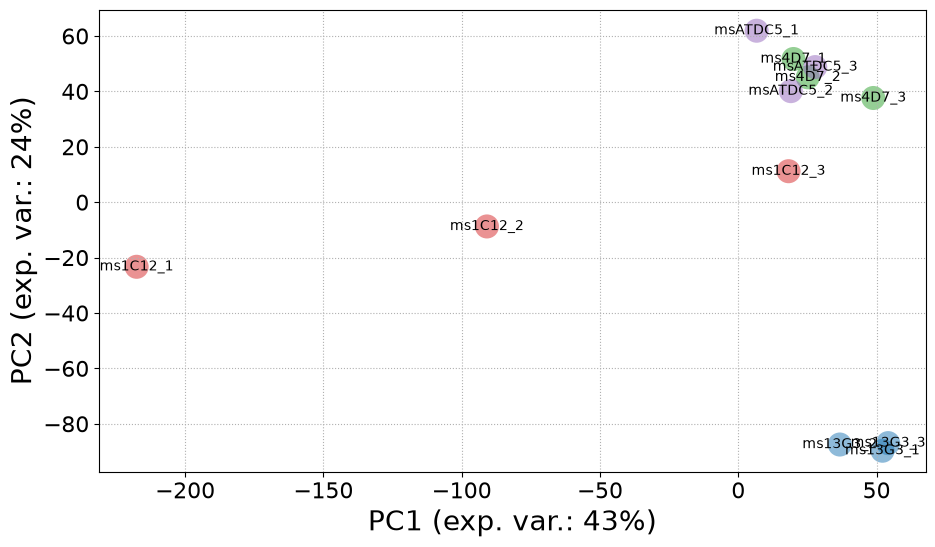

In [27]:
for i in range(len(new)):

    name = pca_substantial_expression.index[i]

    # colors
    if 'ms13G3' in name:
        the_color = 'tab:blue'
    elif 'ms1C12' in name:
        the_color = 'tab:red'
    elif 'ms4D7' in name:
        the_color = 'tab:green'
    elif 'msATDC5' in name:
        the_color = 'tab:purple'
    else:
        print('error')
    
    matplotlib.pyplot.scatter(new[i,0], new[i,1], s=300, c=the_color, marker='o', alpha=0.5, edgecolors='none')
    epsilon=0; matplotlib.pyplot.text(new[i,0]+epsilon, new[i,1]+epsilon, name, size=10, va='center', ha='center', alpha=1)


    legend_elements = [
        matplotlib.lines.Line2D([], [], marker='o', linestyle='none', markersize=16, markerfacecolor='white', markeredgecolor='black'),
        matplotlib.lines.Line2D([], [], marker='s', linestyle='none', markersize=16, markerfacecolor='white', markeredgecolor='black'),
        matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='black',    edgecolor='white', alpha=2/3),
        matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:blue',    edgecolor='white', alpha=2/3),
        matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:red',    edgecolor='white', alpha=2/3),
]    
    #matplotlib.pyplot.legend(legend_elements, ['AEG13', 'AEG14', 'DMSO', 'AZM', 'EP317'], 
    #                         ncol=1, loc='upper left', bbox_to_anchor=(1.05, 1))
    
matplotlib.pyplot.xlabel('PC1 (exp. var.: {}%)'.format(int(explained[0]*100)))
matplotlib.pyplot.ylabel('PC2 (exp. var.: {}%)'.format(int(explained[1]*100)))
matplotlib.pyplot.grid(ls=':')

matplotlib.pyplot.show()

In [ ]:
# distributions

In [23]:
log2_tpm_PO = numpy.log2(expression + 1)
log2_tpm_PO.head()

,ms13G3_3,ms13G3_1,ms13G3_2,ms1C12_1,ms1C12_2,ms1C12_3,ms4D7_1,ms4D7_2,ms4D7_3,msATDC5_1,msATDC5_2,msATDC5_3
ENSMUSG00000000001.5,6.580126,6.521265,6.539689,5.391353,5.921558,6.383891,6.465292,6.440107,6.651100,6.580365,6.557760,6.489559
ENSMUSG00000000003.16,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSMUSG00000000028.16,5.158536,5.269195,4.769913,3.578595,4.055192,4.370869,3.550185,3.773682,4.026273,3.659225,4.048715,4.190912
ENSMUSG00000000031.18,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.199247,0.000000,0.000000,0.000000
ENSMUSG00000000037.18,0.919786,0.879363,0.698348,1.173607,2.032641,2.532474,2.076161,2.374264,2.530978,1.994882,2.616543,2.558901


14.495479474902112


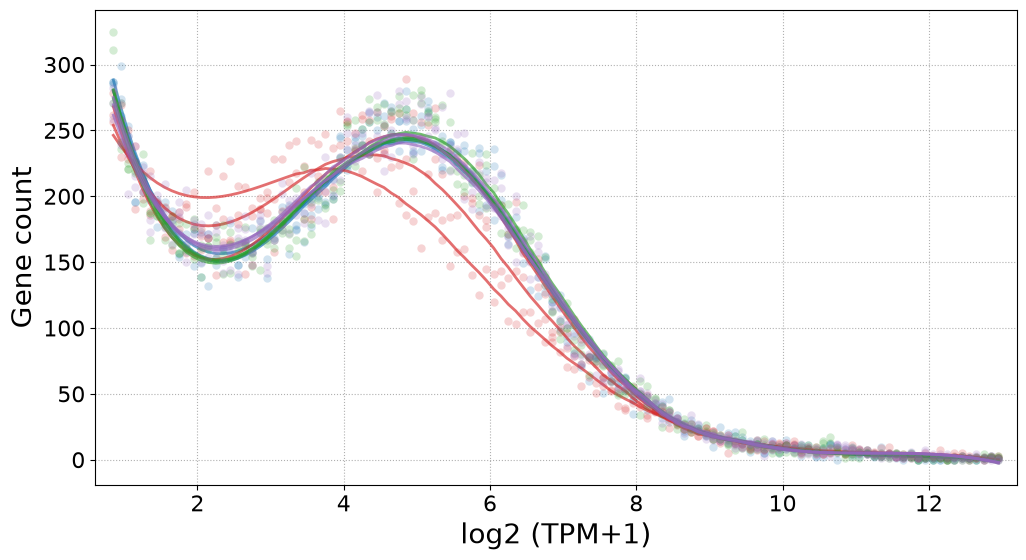

In [25]:
found_max = 17
number_of_bins = int(found_max*10)

absolute_max = 0
working_samples = log2_tpm_PO.columns.to_list()

most_likely_expressions = []
all_hats = []
for i in range(len(working_samples)):

    name = working_samples[i]

    # colors
    if 'ms13G3' in name:
        the_color = 'tab:blue'
    elif 'ms1C12' in name:
        the_color = 'tab:red'
    elif 'ms4D7' in name:
        the_color = 'tab:green'
    elif 'msATDC5' in name:
        the_color = 'tab:purple'
    else:
        print('error')
    

    
    log2TPM = log2_tpm_PO.loc[:, name]
    if max(log2TPM) > absolute_max:
        absolute_max = max(log2TPM)
                
    hist, bin_edges = numpy.histogram(log2TPM, bins=number_of_bins, range=(0, found_max))
    half_bin = (bin_edges[1] - bin_edges[0])/2
    x = bin_edges + half_bin
    x = x[:-1]
  
    plotting_x = x[8:-40]
    plotting_hist = hist[8:-40]
    #print(plotting_x)
    
    matplotlib.pyplot.plot(plotting_x, plotting_hist, 'o', alpha=1/5, mec='none', color=the_color)
    yhat = scipy.signal.savgol_filter(plotting_hist, 51, 3)

    matplotlib.pyplot.plot(plotting_x, yhat, '-', lw=2, alpha=2/3, color=the_color)
    
matplotlib.pyplot.xlim([numpy.min(plotting_x)-0.25, numpy.max(plotting_x)+0.25])

#matplotlib.pyplot.legend(legend_elements, ['Day 0', 'Day 7', 'Day 15', 'Day 21', 'Day 28', 'Day 35'], ncol=1, loc='upper left', bbox_to_anchor=(1.05, 1))

#legend_elements = [
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='black',      edgecolor='white', alpha=2/3),
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:blue',    edgecolor='white', alpha=2/3),
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='gold',    edgecolor='white', alpha=2/3),
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:orange',    edgecolor='white', alpha=2/3),
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:red',    edgecolor='white', alpha=2/3),
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:purple',    edgecolor='white', alpha=2/3),
#]    

matplotlib.pyplot.xlabel('log2 (TPM+1)')
matplotlib.pyplot.ylabel('Gene count')
matplotlib.pyplot.grid(ls=':')

matplotlib.pyplot.tight_layout()

print(absolute_max)